# Proyecto: 120 years of Olympic history
Analisis exploratorio de datos usando Pandas

**Integrantes:**
- Julian Andres Velandia Cortes

## 1. Cargar cada conjunto de datos 

In [5]:
import pandas as pd

df_athlete = pd.read_csv('../data/athlete_events.csv')
df_regions = pd.read_csv('../data/noc_regions.csv')

## 2. Descripcion de las variables

**Dataset athlete_events.csv:**
* **ID:** Identificador de cada atleta.
* **Name:** Nombre del atleta.
* **Sex:** Sexo del atleta (M o F).
* **Age:** Edad del atleta en anios.
* **Height:** Estatura en centimetros.
* **Weight:** Peso en kilogramos.
* **Team:** Nombre del equipo o pais.
* **NOC:** Codigo de 3 letras del Comite Olimpico Nacional.
* **Games:** Anio y temporada de los juegos.
* **Year:** Anio de la edicion.
* **Season:** Temporada (Summer o Winter).
* **City:** Ciudad sede.
* **Sport:** Deporte general.
* **Event:** Prueba especifica en la que compitio.
* **Medal:** Medalla ganada (Gold, Silver, Bronze o vacio/NaN).

**Dataset noc_regions.csv:**
* **NOC:** Codigo de 3 letras del Comite Olimpico Nacional.
* **region:** Nombre del pais o region geografica.
* **notes:** Notas adicionales sobre la region o territorio.

## 3. Estadisticas basicas

In [6]:
# 3. generar las estadísticas basicas de cada dataframe y comparaciones
display(df_athlete.describe(include='all'))
display(df_regions.describe(include='all'))

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
count,271116.000000,271116,271116,261642.000000,210945.000000,208241.000000,271116,271116,271116,271116.000000,271116,271116,271116,271116,39783
unique,NaN,134732,2,NaN,NaN,NaN,1184,230,51,NaN,2,42,66,765,3
top,NaN,Robert Tait McKenzie,M,NaN,NaN,NaN,United States,USA,2000 Summer,NaN,Summer,London,Athletics,Football Men's Football,Gold
freq,NaN,58,196594,NaN,NaN,NaN,17847,18853,13821,NaN,222552,22426,38624,5733,13372
mean,68248.954396,NaN,NaN,25.556898,175.338970,70.702393,NaN,NaN,NaN,1978.378480,NaN,NaN,NaN,NaN,NaN
std,39022.286345,NaN,NaN,6.393561,10.518462,14.348020,NaN,NaN,NaN,29.877632,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,10.000000,127.000000,25.000000,NaN,NaN,NaN,1896.000000,NaN,NaN,NaN,NaN,NaN
25%,34643.000000,NaN,NaN,21.000000,168.000000,60.000000,NaN,NaN,NaN,1960.000000,NaN,NaN,NaN,NaN,NaN
50%,68205.000000,NaN,NaN,24.000000,175.000000,70.000000,NaN,NaN,NaN,1988.000000,NaN,NaN,NaN,NaN,NaN
75%,102097.250000,NaN,NaN,28.000000,183.000000,79.000000,NaN,NaN,NaN,2002.000000,NaN,NaN,NaN,NaN,NaN


,NOC,region,notes
count,230,227,21
unique,230,206,21
top,AFG,Germany,Netherlands Antilles
freq,1,4,1


**Comparacion entre los dataframes:**
El dataframe ""df_athlete"" tiene 271,116 filas y 15 columnas (combina variables numericas como edad, peso, estatura y ano con variables de texto), donde cada fila es la participacion de un atleta en una prueba y existen 226 codigos NOC distintos. El dataframe ""df_regions"" tiene 230 filas y 3 columnas (todas de texto), donde cada fila representa un codigo NOC unico con su respectiva region.

## 4. Creación de la variable IMC
Fórmula: Peso / (Estatura/100)^2

In [7]:

df_athlete['IMC'] = df_athlete['Weight'] / ((df_athlete['Height'] / 100) ** 2)
df_athlete[['Weight', 'Height', 'IMC']].head()

,Weight,Height,IMC
0,80.0,180.0,24.691358
1,60.0,170.0,20.761246
2,NaN,NaN,NaN
3,NaN,NaN,NaN
4,82.0,185.0,23.959094


**¿Qué opina de esta nueva variable? ¿Tiene el mismo sentido en todos los deportes?**

El IMC sirve para darnos una idea general de la relacion entre el peso y la estatura de una persona, pero en atletas olimpicos no es una medida muy confiable para evaluar su estado fisico porque la formula no diferencia entre grasa y masa muscular.

Por eso mismo, no tiene el mismo sentido en todos los deportes. Cada disciplina exige un tipo de cuerpo muy distinto: por ejemplo, un atleta de levantamiento de pesas o de lucha va a tener un IMC muy alto (que en una tabla normal saldria como "sobrepeso"), pero en realidad ese peso es puro musculo necesario para su deporte. En cambio, deportistas de gimnasia o maraton suelen tener un IMC mucho mas bajo porque necesitan ser ligeros. Compararlos a todos con la misma regla del IMC no refleja su verdadero rendimiento ni su salud.

## 5. Fusion (merge) de atletas y regiones

In [8]:
#fucionar el dataframe de atletas con el de regiones usando NOC
df_merged = pd.merge(df_athlete, df_regions, on='NOC', how='left')

# verificar el numero de filas antes y despues del cruce
print("Filas antes del merge:", len(df_athlete))
print("Filas despues del merge:", len(df_merged))

# revisar cuantos registros quedan sin region asociada
sin_region = df_merged['region'].isna().sum() # esto de .isna() revisa que celdas estan vacias 
print("Filas sin region:", sin_region)
print("Codigos NOC sin region:", df_merged[df_merged['region'].isna()]['NOC'].unique()) #esto del .unique() es para obtener los valores distintos (sin repetir)

Filas antes del merge: 271116
Filas despues del merge: 271116
Filas sin region: 370
Codigos NOC sin region: <StringArray>
['SGP', 'ROT', 'UNK', 'TUV']
Length: 4, dtype: str


* **¿Por que cree que ocurre esto?** Quedan filas sin region porque en el dataset de atletas existen codigos NOC historicos o especiales (como "ROT" de refugiados o "TUV" de Tuvalu) que no tienen un pais asociado en la tabla pequena de regiones.
* **¿Que tipo de fusion (how) utilizo y por que?** Se utilizo "how='left'". Esto garantiza que se mantengan absolutamente todas las filas del dataframe principal de atletas sin perder ningun registro, trayendo la region cuando coincide el codigo NOC y dejando vacio ("NaN") donde no hay coincidencia.

## 6. Creacion de la variable binaria de medallas

In [9]:
# 6. Crear variable binaria llamada 'medalla' (1 si gano, 0 si no gano)
# .notna() devuelve True si hay medalla y False si esta vacio (NaN)
# .astype(int) convierte True en 1 y False en 0
df_merged['medalla'] = df_merged['Medal'].notna().astype(int)

# Mostrar las primeras filas para verificar
display(df_merged[['Name', 'Sport', 'Medal', 'medalla']].head(10))

# Comparar numero de filas vs numero de atletas unicos (ID)
# .nunique() cuenta los ID sin repetir
total_filas = len(df_merged)
atletas_unicos = df_merged['ID'].nunique()

print("Total de filas:", total_filas)
print("Total de atletas unicos (ID):", atletas_unicos)

,Name,Sport,Medal,medalla
0,A Dijiang,Basketball,NaN,0
1,A Lamusi,Judo,NaN,0
2,Gunnar Nielsen Aaby,Football,NaN,0
3,Edgar Lindenau Aabye,Tug-Of-War,Gold,1
4,Christine Jacoba Aaftink,Speed Skating,NaN,0
5,Christine Jacoba Aaftink,Speed Skating,NaN,0
6,Christine Jacoba Aaftink,Speed Skating,NaN,0
7,Christine Jacoba Aaftink,Speed Skating,NaN,0
8,Christine Jacoba Aaftink,Speed Skating,NaN,0
9,Christine Jacoba Aaftink,Speed Skating,NaN,0


Total de filas: 271116
Total de atletas unicos (ID): 135571



* **¿Que hacemos con los valores vacios de Medal?** No los borramos. Como un valor vacio ("NaN") significa que el atleta no gano medalla en esa prueba, al crear la columna binaria "medalla" esos vacios pasan a ser "0" y las medallas ganadas pasan a ser "1".
* **Filas vs. atletas unicos:** El dataset tiene 271,116 filas pero solo 135,571 atletas unicos ("ID"), porque un mismo atleta aparece varias veces si compitio en distintas pruebas o ediciones.
* **¿Que implica esto para contar medallas?** Si sumamos la columna "medalla", estamos contando participaciones premiadas (medallas entregadas a personas), no el medallero oficial por pais. En deportes de equipo (como futbol o baloncesto), cada jugador del equipo ganador tiene su propia fila con "1", asi que una sola medalla del pais se contaria varias veces.

## 7. Analisis de representatividad de los datos

In [10]:

# Ver el primer y ultimo anio registrado (.min y .max sacan el menor y mayor valor)
print("anio minimo:", df_merged['Year'].min())
print("anio maximo:", df_merged['Year'].max())

# Contar cuantos paises y deportes distintos hay (.nunique cuenta valores unicos sin repetir)
print("Total de regiones distintas:", df_merged['region'].nunique())
print("Total de deportes distintos:", df_merged['Sport'].nunique())

# Contar cuantos registros hay por sexo (.value_counts cuenta cuantas veces sale cada opcion)
print(df_merged['Sex'].value_counts())

# Contar cuantos registros hay en juegos de veranio vs invierno
print(df_merged['Season'].value_counts())

# Mostrar los 5 paises con mas participaciones
print(df_merged['region'].value_counts().head(5))

anio minimo: 1896
anio maximo: 2016
Total de regiones distintas: 205
Total de deportes distintos: 66
Sex
M    196594
F     74522
Name: count, dtype: int64
Season
Summer    222552
Winter     48564
Name: count, dtype: int64
region
USA        18853
Germany    15883
France     12758
UK         12256
Russia     11692
Name: count, dtype: int64


**Analisis de representatividad:**
El conjunto de datos cubre 120 anos de historia (1896 a 2016) con 205 regiones y 66 deportes, pero no es completamente equilibrado en todos los aspectos:
* **Por sexo:** Hay mucha mas participacion de hombres que de mujeres, ya que en las primeras ediciones de los Juegos Olimpicos las mujeres casi no podian competir.
* **Por temporada:** Hay muchos mas datos de los juegos de verano ("Summer") que de invierno ("Winter"), porque los de verano empezaron antes y tienen mas deportes.
* **Por pais:** Potencias como Estados Unidos, Francia, Reino Unido e Italia concentran una gran parte de los registros, mientras que paises mas pequenos tienen muy pocas participaciones.

## 8. Analisis de datos faltantes

In [11]:

# 8. Contar cuantos datos faltantes hay en todo el dataset
faltantes = df_merged.isna().sum()
porcentaje = (faltantes / len(df_merged) * 100).round(2)

tabla_faltantes = pd.DataFrame({
    'Cantidad_faltantes': faltantes,
    'Porcentaje': porcentaje
})

display(tabla_faltantes[tabla_faltantes['Cantidad_faltantes'] > 0])

# Comparar porcentaje de faltantes antes de 1960 vs desde 1960 en adelante
# Filtramos el dataframe en dos grupos usando la columna 'Year'
antes_1960 = df_merged[df_merged['Year'] < 1960]
desde_1960 = df_merged[df_merged['Year'] >= 1960]

# Calculamos el porcentaje de vacios en cada epoca para las columnas fisicas
columnas = ['Age', 'Height', 'Weight', 'IMC']
comp_epocas = pd.DataFrame({
    'Antes': (antes_1960[columnas].isna().sum() / len(antes_1960) * 100).round(2),
    'Desde': (desde_1960[columnas].isna().sum() / len(desde_1960) * 100).round(2)
})
print("\nPorcentaje de datos faltantes por epoca:")
display(comp_epocas)

,Cantidad_faltantes,Porcentaje
Age,9474,3.49
Height,60171,22.19
Weight,62875,23.19
Medal,231333,85.33
IMC,64263,23.70
region,370,0.14
notes,266077,98.14



Porcentaje de datos faltantes por epoca:


,Antes,Desde
Age,13.47,0.53
Height,79.06,5.32
Weight,82.28,5.66
IMC,83.62,5.92


**Analisis de datos faltantes (Punto 8):**
* **Medal (85.33%):** Es la que mas vacios tiene, pero no es un error. Significa simplemente que ese atleta no gano medalla en esa prueba.
* **notes (98.13%):** Casi toda esta vacia porque solo se llena para regiones especiales que necesitan una aclaracion historica.
* **Height, Weight, IMC y Age:** Faltan sobre todo en las primeras ediciones de los Juegos Olimpicos (finales de 1800 y principios de 1900), cuando no se registraban las medidas fisicas de todos los deportistas.
* **region (0.14%):** Son los pocos codigos NOC especiales que vimos en el punto 5.

**¿Que decision tomamos con estos faltantes?**
No conviene usar "dropna()" para borrar las filas vacias, porque borrariamos a todos los atletas que no ganaron medalla y gran parte de la historia antigua de los juegos. Lo mejor es dejar los valores vacios como estan: para "Medal" ya creamos la columna "tiene_medalla" (1 y 0), y para los calculos numericos de edad, peso, estatura e IMC, Pandas ignora automaticamente los "NaN" sin dañar los promedios.

* **Cambio segun la epoca (antes vs. despues de 1960):** Si cambia mucho. Antes de 1960 faltaba la mayoria de los datos fisicos (mas del 60% en estatura, peso e IMC, y mas del 10% en edad). A partir de 1960 el registro mejoro bastante y los faltantes bajaron a menos del 10% en peso y estatura, y a menos del 1% en edad.

## 9. Preguntas especificas sobre los datos

In [12]:
# 9(a) 
# .mean() saca el promedio y round(..., 2) redondea a 2 decimales
edad_promedio = round(df_merged['Age'].mean(), 2)
print("Edad promedio de los atletas:", edad_promedio, "años")

# 9(b) 
# .value_counts() cuenta cuantas veces aparece el 0 y cuantas el 1
print(df_merged['medalla'].value_counts())

# 9(c)
# Primero filtramos solo las filas donde Medal sea igual a 'Gold'
solo_oro = df_merged[df_merged['Medal'] == 'Gold']
estatura_oro = round(solo_oro['Height'].mean(), 2)
print("Estatura promedio de ganadores de oro:", estatura_oro, "cm")

# 9(d) 
# .nunique() cuenta valores unicos sin repetir
ediciones = df_merged['Games'].nunique()
paises_noc = df_merged['NOC'].nunique()
print("Ediciones distintas:", ediciones, " Paises (NOC) distintos:", paises_noc)

# 9(e)
print("Edad mas joven:", df_merged['Age'].min(), " Edad mas vieja:", df_merged['Age'].max())

# 9(f)
print(df_merged['Season'].value_counts())

# 9(g) 
# Agrupamos por ID de atleta y contamos en cuantas ediciones ('Games') distintas estuvo cada uno
ediciones_por_atleta = df_merged.groupby('ID')['Games'].nunique()

# Contamos cuantos atletas tienen exactamente 1 edicion y cuantos tienen mas de 1
una_edicion = (ediciones_por_atleta == 1).sum()
mas_de_una = (ediciones_por_atleta > 1).sum()

print("Atletas en una sola edicion:", una_edicion)
print("Atletas en mas de una edicion:", mas_de_una)

Edad promedio de los atletas: 25.56 años
medalla
0    231333
1     39783
Name: count, dtype: int64
Estatura promedio de ganadores de oro: 177.9 cm
Ediciones distintas: 51  Paises (NOC) distintos: 230
Edad mas joven: 10.0  Edad mas vieja: 97.0
Season
Summer    222552
Winter     48564
Name: count, dtype: int64
Atletas en una sola edicion: 98450
Atletas en mas de una edicion: 37121



* La edad promedio de los atletas ronda los 25 anos, pero existe un rango extremo entre el participante mas joven (10 anos) y el mayor (97 anos, principalmente en antiguas competencias de arte).
* La gran mayoria de los registros terminan sin medalla (mas del 85%), lo cual es esperado porque solo tres competidores o equipos suben al podio por prueba.
* Los ganadores de medalla de oro tienen una estatura promedio ligeramente superior al promedio general del dataset.
* Hay 51 ediciones registradas y 230 codigos NOC distintos, con una clara mayoria de registros en los juegos de verano ("Summer") frente a los de invierno ("Winter").
* La mayoria de los atletas unicos compitieron en una sola edicion de los Juegos Olimpicos, mientras que un grupo menor logro clasificar a dos o mas ediciones.

## 10. Verificacion de hipotesis: conteos y tasas de medallas

In [13]:

# count = participaciones, sum = total de medallas, mean = tasa (proporcion)

# a) 
print("a) Mujeres vs Hombres:")
display(df_merged.groupby('Sex')['medalla'].agg(['count', 'sum', 'mean']))

# Para las preguntas b y c quitamos las filas que no tienen edad
df_edad = df_merged.dropna(subset=['Age'])

es_menor = df_edad['Age'] < 18
display(df_edad.groupby(es_menor)['medalla'].agg(['count', 'sum', 'mean'])) #b) Menores de 18 (True) vs Adultos (False)

edad_extrema = (df_edad['Age'] < 18) | (df_edad['Age'] >= 35)
display(df_edad.groupby(edad_extrema)['medalla'].agg(['count', 'sum', 'mean'])) # c) Menores de 18 o de 35 o mas (True) vs Entre 18 y 34 (False)


es_usa = df_merged['NOC'] == 'USA'
display(df_merged.groupby(es_usa)['medalla'].agg(['count', 'sum', 'mean'])) # d) Estados Unidos (True) vs Otros paises (False)

display(df_merged.groupby('Season')['medalla'].agg(['count', 'sum', 'mean'])) # e) Verano (Summer) vs Invierno (Winter)

a) Mujeres vs Hombres:


,count,sum,mean
Sex,,,
F,74522,11253,0.151002
M,196594,28530,0.145121


,count,sum,mean
Age,,,
False,249134,37872,0.152015
True,12508,1179,0.094260


,count,sum,mean
Age,,,
False,229617,35066,0.152715
True,32025,3985,0.124434


,count,sum,mean
NOC,,,
False,252263,34146,0.135359
True,18853,5637,0.298998


,count,sum,mean
Season,,,
Summer,222552,34088,0.153169
Winter,48564,5695,0.117268


## 11. Grupos de participacion por numero de pruebas (n_pruebas)

In [14]:
# 11.1 
# Agrupamos por ID, Games y Sport, y contamos las pruebas con .count()
# .reset_index() vuelve a dejar el resultado como una tabla normal
pruebas = df_merged.groupby(['ID', 'Games', 'Sport'])['Event'].count().reset_index()

# Le cambiamos el nombre a la columna 'Event' por 'n_pruebas'
pruebas = pruebas.rename(columns={'Event': 'n_pruebas'})

# 11.2 
def clasificar_grupo(n):
    if n == 1:
        return 'Grupo 1: una sola prueba'
    elif n <= 3:
        return 'Grupo 2: participacion moderada'
    else:
        return 'Grupo 3: participacion alta'

# .apply() le pasa nuestra funcion a cada numero de la columna 'n_pruebas'
pruebas['grupo'] = pruebas['n_pruebas'].apply(clasificar_grupo)

# Contar cuantos quedaron en cada grupo
print(pruebas['grupo'].value_counts())

# 11.3 
tabla_deportes = pd.crosstab(pruebas['Sport'], pruebas['grupo'])
display(tabla_deportes)

# Sacar los 5 deportes mas frecuentes de cada grupo ordenando de mayor a menor
print(tabla_deportes['Grupo 1: una sola prueba'].sort_values(ascending=False).head(5))

print(tabla_deportes['Grupo 2: participacion moderada'].sort_values(ascending=False).head(5))

print(tabla_deportes['Grupo 3: participacion alta'].sort_values(ascending=False).head(5))

grupo
Grupo 1: una sola prueba           141046
Grupo 2: participacion moderada     39510
Grupo 3: participacion alta          7613
Name: count, dtype: int64


grupo,Grupo 1: una sola prueba,Grupo 2: participacion moderada,Grupo 3: participacion alta
Sport,,,
Aeronautics,1,0,0
Alpine Skiing,1249,2566,305
Alpinism,25,0,0
Archery,767,747,10
Art Competitions,1443,443,162
...,...,...,...
Tug-Of-War,170,0,0
Volleyball,3404,0,0
Water Polo,3846,0,0


Sport
Athletics    23942
Rowing        9872
Football      6745
Wrestling     6569
Sailing       6300
Name: Grupo 1: una sola prueba, dtype: int64
Sport
Athletics        6400
Swimming         5783
Fencing          3244
Equestrianism    2649
Cycling          2643
Name: Grupo 2: participacion moderada, dtype: int64
Sport
Gymnastics              3690
Swimming                 997
Cross Country Skiing     824
Biathlon                 386
Alpine Skiing            305
Name: Grupo 3: participacion alta, dtype: int64


## 12. Proporcion por sexo, grupo etario, medidas fisicas y medalla

In [15]:
# 12.1
# .copy() creamos una tabla aparte para trabajar sin modificar df_merged
df_12 = df_merged.dropna(subset=['Age']).copy()

# 12.2 
def clasificar_edad(edad):
    if edad < 18:
        return 'Menores'
    elif edad <= 34:
        return 'Jovenes adultos'
    else:
        return 'Mayores'

df_12['grupo_etario'] = df_12['Age'].apply(clasificar_edad)

# 12.3 
# .notna() revisa que no este vacio, y el simbolo & significa "y" (ambos deben tener dato)
# True = tiene ambos datos | False = le falta estatura, peso o ambos
df_12['tiene_medidas'] = df_12['Height'].notna() & df_12['Weight'].notna()

# 12.4 
# En las filas ponemos Sexo y grupo_etario
# En las columnas ponemos tiene_medidas (False/True) y medalla (0/1)
# normalize='index' hace que cada fila sume 100%
tabla_12 = pd.crosstab(
    [df_12['Sex'], df_12['grupo_etario']],
    [df_12['tiene_medidas'], df_12['medalla']],
    normalize='index'
) * 100

display(tabla_12.round(2))

tiene_medidas        False        True        
medalla                  0     1      0      1
Sex grupo_etario                              
F   Jovenes adultos   7.99  1.11  75.93  14.97
    Mayores          14.17  2.05  71.98  11.80
    Menores          12.30  1.49  78.20   8.01
M   Jovenes adultos  19.30  3.85  65.73  11.13
    Mayores          41.75  8.37  43.78   6.10
    Menores          24.97  4.38  65.83   4.82

**Analisis y conclusion del Punto 12:**
* **¿Que se hizo con los atletas sin edad registrada?** Se excluyeron de este analisis usando "dropna(subset=['Age'])", ya que sin ese dato es imposible ubicarlos en uno de los tres grupos etarios definidos.
* **Lectura de la tabla:** Cada fila (combinacion de sexo y grupo etario) suma 100%, repartido en cuatro casos: sin medidas y sin medalla ("False, 0"), sin medidas y con medalla ("False, 1"), con medidas y sin medalla ("True, 0") y con medidas y con medalla ("True, 1").
* **Conclusion:** En casi todos los grupos, la mayor proporcion corresponde a atletas que **si tienen estatura y peso registrados y no ganaron medalla** ("True, 0"). Las mujeres presentan un porcentaje mas alto de registros con medidas completas que los hombres, sobre todo frente a los hombres **Mayores (35 anos o mas)**, donde hay una proporcion mucho mayor sin datos de estatura y peso ("False") porque ese grupo concentra muchos participantes de las primeras ediciones de los Juegos Olimpicos. En cuanto a medallas, la proporcion de ganadores ("1") es minoritaria en todos los grupos, siendo mayor entre quienes si tienen sus medidas registradas debido a que corresponden principalmente a la epoca moderna con mas competencias.

## 13. Graficos y analisis visual

In [16]:
import matplotlib.pyplot as plt
import os

# Crear automaticamente las carpetas de outputs si no existen
os.makedirs('../outputs/graficos', exist_ok=True)
os.makedirs('../outputs/tablas', exist_ok=True)


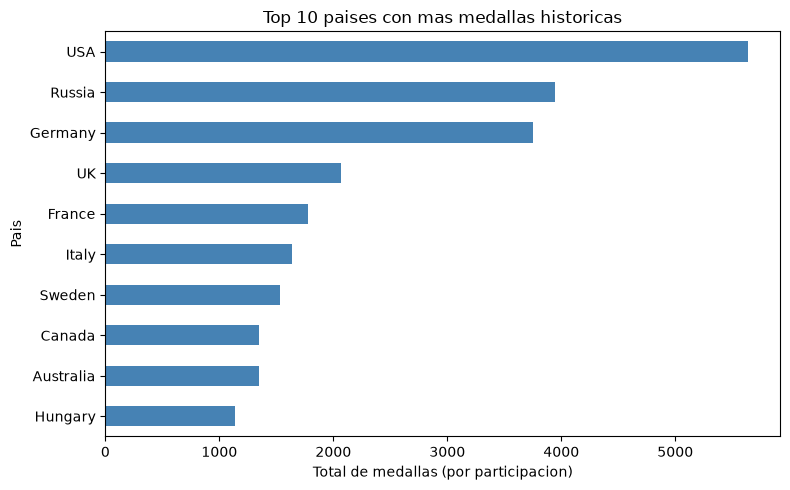

In [17]:
# Grafico 1: Top 10 paises con mas medallas
top_paises = df_merged.groupby('region')['medalla'].sum().sort_values(ascending=False).head(10)

# Guardar tabla resumen en CSV
top_paises.to_csv('../outputs/tablas/top10_paises_medallas.csv')

# Hacer grafico de barras horizontales (barh)
plt.figure(figsize=(8, 5))
top_paises.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 10 paises con mas medallas historicas')
plt.xlabel('Total de medallas (por participacion)')
plt.ylabel('Pais')
plt.tight_layout()
plt.savefig('../outputs/graficos/grafico1_top10_paises.png')
plt.show()

**Interpretacion Grafico 1:** Estados Unidos lidera de forma amplia el total historico de medallas por participacion, seguido por Rusia, Alemania, Reino Unido e Italia. La diferencia entre el primer lugar y el resto muestra una fuerte concentracion historica de podios en unas pocas potencias deportivas.

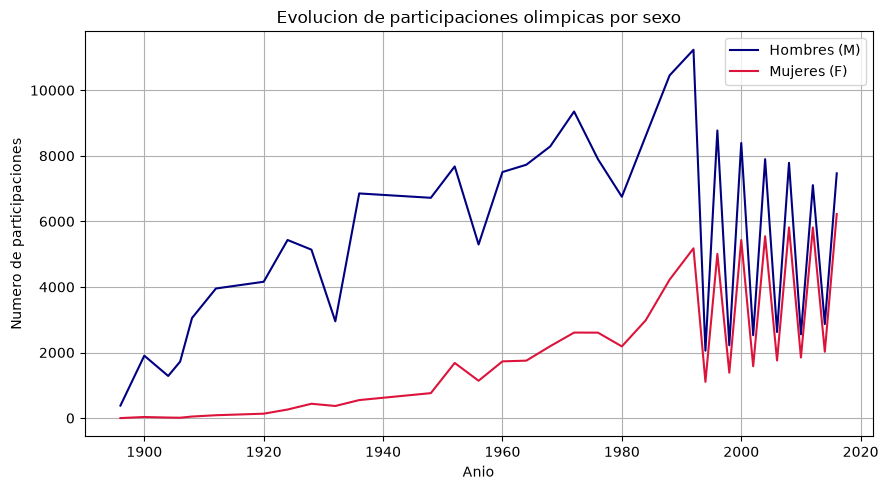

In [18]:
# Grafico 2: Participaciones por anio separadas por sexo
# pd.crosstab cuenta cuantas filas hay por cada anio y sexo
part_anio_sexo = pd.crosstab(df_merged['Year'], df_merged['Sex'])

# Guardar tabla resumen en CSV
part_anio_sexo.to_csv('../outputs/tablas/participacion_anio_sexo.csv')

# Hacer grafico de lineas
plt.figure(figsize=(9, 5))
plt.plot(part_anio_sexo.index, part_anio_sexo['M'], label='Hombres (M)', color='navy')
plt.plot(part_anio_sexo.index, part_anio_sexo['F'], label='Mujeres (F)', color='crimson')
plt.title('Evolucion de participaciones olimpicas por sexo')
plt.xlabel('Anio')
plt.ylabel('Numero de participaciones')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('../outputs/graficos/grafico2_participacion_sexo.png')
plt.show()

**Interpretacion Grafico 2:** Durante la primera mitad del siglo XX la participacion femenina era minima frente a la masculina. A partir de la decada de 1980 el crecimiento de las mujeres se acelera de forma constante hasta acercarse mucho al nivel de los hombres en las ediciones recientes. Las caidas bruscas en la linea corresponden a los anios en que solo se realizaron Juegos de Invierno (desde 1994 se alternan cada dos anios con los de Verano).

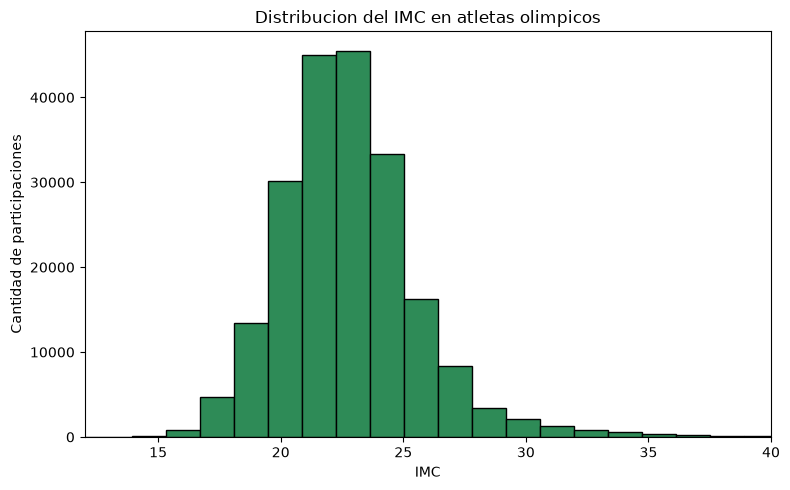

In [19]:
# Grafico 3: Histograma del IMC (quitando valores vacios)
imc_limpio = df_merged['IMC'].dropna()

plt.figure(figsize=(8, 5))
plt.hist(imc_limpio, bins=40, color='seagreen', edgecolor='black')
plt.title('Distribucion del IMC en atletas olimpicos')
plt.xlabel('IMC')
plt.ylabel('Cantidad de participaciones')
plt.xlim(12, 40) # limitar eje X para ver mejor donde se concentran los datos
plt.tight_layout()
plt.savefig('../outputs/graficos/grafico3_distribucion_imc.png')
plt.show()

**Interpretacion Grafico 3:** La gran mayoria de los atletas olimpicos se concentra entre un IMC de 20 y 25, con un pico cercano a 22. Sin embargo, existe una cola hacia la derecha (valores entre 26 y 35) que corresponde a deportes de fuerza, lanzamientos y combate donde predomina una alta masa muscular.

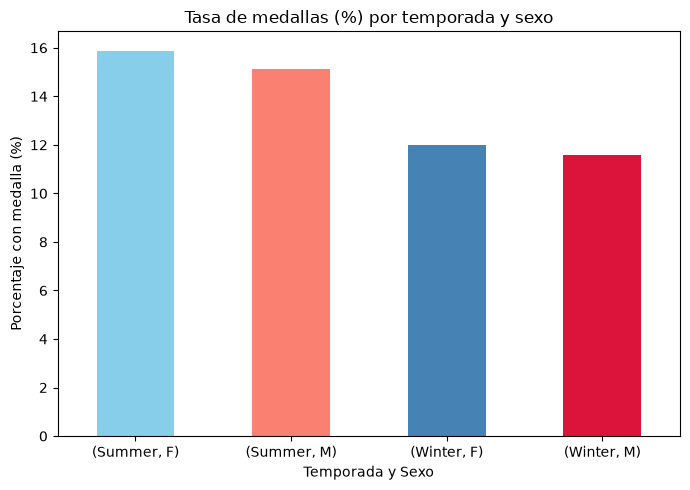

In [20]:
# Grafico 4: Porcentaje de participaciones con medalla segun temporada y sexo
tasa_temp_sexo = df_merged.groupby(['Season', 'Sex'])['medalla'].mean() * 100

# Guardar tabla resumen en CSV
tasa_temp_sexo.round(2).to_csv('../outputs/tablas/tasa_medallas_temporada_sexo.csv')

plt.figure(figsize=(7, 5))
tasa_temp_sexo.plot(kind='bar', color=['skyblue', 'salmon', 'steelblue', 'crimson'])
plt.title('Tasa de medallas (%) por temporada y sexo')
plt.xlabel('Temporada y Sexo')
plt.ylabel('Porcentaje con medalla (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/graficos/grafico4_tasa_medallas.png')
plt.show()

**Interpretacion Grafico 2:** Durante la primera mitad del siglo XX la participacion femenina era minima frente a la masculina. A partir de la decada de 1980 el crecimiento de las mujeres se acelera de forma constante hasta acercarse mucho al nivel de los hombres en las ediciones recientes. Las caidas bruscas en la linea corresponden a los anios en que solo se realizaron Juegos de Invierno (desde 1994 se alternan cada dos anios con los de Verano).

## 14. Quienes tenian mas probabilidades de ganar una medalla?

In [21]:
# 14. Calcular la tasa de medallas %

# 5 paises con mayor tasa de medallas (solo paises con al menos 500 participaciones)
paises_resumen = df_merged.groupby('region')['medalla'].agg(['count', 'mean'])
paises_grandes = paises_resumen[paises_resumen['count'] >= 500]
paises_grandes['tasa_%'] = (paises_grandes['mean'] * 100).round(2)

display(paises_grandes.sort_values(by='tasa_%', ascending=False).head(5)[['count', 'tasa_%']])

# Top 5 deportes con mayor tasa de medallas (solo deportes con al menos 500 participaciones)
deportes_resumen = df_merged.groupby('Sport')['medalla'].agg(['count', 'mean'])
deportes_grandes = deportes_resumen[deportes_resumen['count'] >= 500]
deportes_grandes['tasa_%'] = (deportes_grandes['mean'] * 100).round(2)

display(deportes_grandes.sort_values(by='tasa_%', ascending=False).head(5)[['count', 'tasa_%']])

,count,tasa_%
region,,
Russia,11692,33.76
USA,18853,29.90
Germany,15883,23.65
Pakistan,562,21.53
Norway,4960,20.83


,count,tasa_%
Sport,,
Baseball,894,37.58
Handball,3665,28.92
Volleyball,3404,28.47
Hockey,5417,28.21
Rowing,10595,27.80
